In [1]:
!python --version

Python 3.13.18


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import statsmodels.api as sm

In [3]:
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})
ANN = 252
TICKERS = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']
IS_START, IS_END = '2023-09-01', '2025-09-30'
OOS_START, OOS_END = '2025-10-01', '2025-12-31'

In [9]:
from pathlib import Path
import pandas as pd
import yfinance as yf

# Same variables as your original code
YF_MAP = {t: t for t in TICKERS}
YF_MAP["^GSPC"] = "SPX"

PRICE_START, PRICE_END = "2023-08-31", "2026-01-01"

# Create data folder if it doesn't exist
Path("data").mkdir(parents=True, exist_ok=True)

# Download from Yahoo Finance
raw = yf.download(
    list(YF_MAP.keys()),
    start=PRICE_START,
    end=PRICE_END,
    auto_adjust=False,
    progress=False,
    group_by="column",
    threads=True,
)

if raw.empty:
    raise ValueError("Yahoo Finance returned no data.")

# Extract Close prices
if isinstance(raw.columns, pd.MultiIndex):
    prices = raw.xs("Close", axis=1, level=0)
else:
    prices = raw[["Close"]].rename(
        columns={"Close": list(YF_MAP.keys())[0]}
    )

# Rename Yahoo ticker symbols and retain original column order
prices = prices.rename(columns=YF_MAP)
expected = TICKERS + ["SPX"]

missing = [t for t in expected if t not in prices.columns]
if missing:
    raise ValueError(f"Missing tickers from Yahoo Finance: {missing}")

prices = prices[expected].copy()
prices.index = pd.to_datetime(prices.index).tz_localize(None)
prices.index.name = "Date"
prices = prices.sort_index().dropna(how="all")

# Save prices to CSV
prices.to_csv("data/prices_yfinance.csv")

PRICE_SOURCE = "yfinance (downloaded)"

print(
    "Price source:", PRICE_SOURCE,
    "| Shape:", prices.shape,
    "| Date range:",
    prices.index.min().date(), "->", prices.index.max().date()
)

display(prices.head())

Price source: yfinance (downloaded) | Shape: (586, 11) | Date range: 2023-08-31 -> 2025-12-31


Ticker,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,SPX
Date,,,,,,,,,,,
2023-08-31,258.0800,54.2033,28.6700,327.7100,554.2000,108.9800,137.3500,295.8900,187.8700,111.1900,4507.6602
2023-09-01,245.0100,53.8567,28.9800,327.4000,557.1100,109.8400,136.8000,296.3800,189.4600,113.5200,4515.7700
2023-09-05,256.4900,53.4233,28.6500,323.7500,558.1900,107.5100,136.7100,300.1500,189.7000,113.5300,4496.8301
2023-09-06,251.9200,53.8233,28.3900,321.1300,559.9500,106.4900,135.3700,299.1700,182.9100,114.5100,4465.4800
2023-09-07,251.4900,54.4900,28.1300,321.9600,573.2300,107.9400,136.2000,298.6700,177.5600,113.9500,4451.1401


In [11]:
from pathlib import Path
import pandas as pd
import urllib.request
import zipfile
import io

Path("data").mkdir(parents=True, exist_ok=True)

url = (
    "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
    "ftp/F-F_Research_Data_5_Factors_2x3_daily_CSV.zip"
)

# Download the official Fama-French daily factor dataset
with urllib.request.urlopen(url) as response:
    zip_data = response.read()

with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    csv_name = next(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )
    content = z.read(csv_name).decode("utf-8-sig")

# Parse the daily factor section
lines = content.splitlines()
header_idx = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith(",Mkt-RF")
)

data_lines = []
for line in lines[header_idx + 1:]:
    first = line.split(",")[0].strip()
    if len(first) == 8 and first.isdigit():
        data_lines.append(line)
    elif data_lines:
        break

ff = pd.read_csv(
    io.StringIO(lines[header_idx] + "\n" + "\n".join(data_lines)),
    index_col=0,
)

ff.index = pd.to_datetime(
    ff.index.astype(str), format="%Y%m%d"
)
ff.index.name = "Date"

ff.to_csv("data/FF5_factors_daily.csv")

print("Saved: data/FF5_factors_daily.csv")
print("Shape:", ff.shape)
print("Date range:", ff.index.min().date(), "to", ff.index.max().date())
print(ff.head())

Saved: data/FF5_factors_daily.csv
Shape: (15918, 6)
Date range: 1963-07-01 to 2026-09-30
            Mkt-RF     SMB     HML     RMW     CMA     RF
Date                                                     
1963-07-01 -0.6700  0.0000 -0.3300 -0.0100  0.1600 0.0100
1963-07-02  0.7900 -0.2600  0.2600 -0.0700 -0.2000 0.0100
1963-07-03  0.6300 -0.1700 -0.1000  0.1800 -0.3400 0.0100
1963-07-05  0.4000  0.0800 -0.2700  0.0900 -0.3400 0.0100
1963-07-08 -0.6300  0.0400 -0.1800 -0.2900  0.1400 0.0100


In [12]:
print('Price source:', PRICE_SOURCE, '|', prices.shape, prices.index.min().date(), '->', prices.index.max().date())
ff = pd.read_csv('data/FF5_factors_daily.csv', index_col=0, parse_dates=True) / 100  # % -> decimals

rets = prices.pct_change().dropna()  # simple daily returns, from the yfinance prices above
if PRICE_SOURCE == 'yfinance (downloaded)':  # save the returns next to the prices (same files as get_returns_yfinance.py)
    rets.round(8).to_csv('data/returns_daily.csv'); np.log1p(rets).round(8).to_csv('data/returns_daily_log.csv')
rf = ff['RF'].reindex(rets.index)

R_is, R_oos = rets.loc[IS_START:IS_END], rets.loc[OOS_START:OOS_END]
rf_is, rf_oos = rf.loc[IS_START:IS_END], rf.loc[OOS_START:OOS_END]

mu = R_is[TICKERS].mean()  # daily mean returns
S = R_is[TICKERS].cov()  # daily covariance matrix
rf_d = rf_is.mean()  # average daily risk-free rate

print(f'In-sample obs: {len(R_is)} ({R_is.index[0].date()} to {R_is.index[-1].date()})')
print(f'Out-of-sample obs: {len(R_oos)} ({R_oos.index[0].date()} to {R_oos.index[-1].date()})')
print(f'Average risk-free rate (annualised): {rf_d*ANN:.2%}')
summary = pd.DataFrame({'Ann. mean': mu*ANN, 'Ann. vol': np.sqrt(np.diag(S)*ANN)}, index=TICKERS)
summary['Sharpe'] = (summary['Ann. mean'] - rf_d*ANN) / summary['Ann. vol']
summary.round(4)

Price source: yfinance (downloaded) | (586, 11) 2023-08-31 -> 2025-12-31
In-sample obs: 521 (2023-09-01 to 2025-09-30)
Out-of-sample obs: 64 (2025-10-01 to 2025-12-31)
Average risk-free rate (annualised): 5.04%


,Ann. mean,Ann. vol,Sharpe
TSLA,0.4581,0.6291,0.6480
WMT,0.3333,0.2115,1.3375
BAC,0.3172,0.2560,1.0418
GS,0.4695,0.2831,1.4806
LLY,0.2170,0.3523,0.4730
MRK,-0.0968,0.2420,-0.6082
GOOG,0.3209,0.2957,0.9146
META,0.5039,0.3618,1.2536
AAPL,0.1851,0.2771,0.4860
XOM,0.0315,0.2222,-0.0851


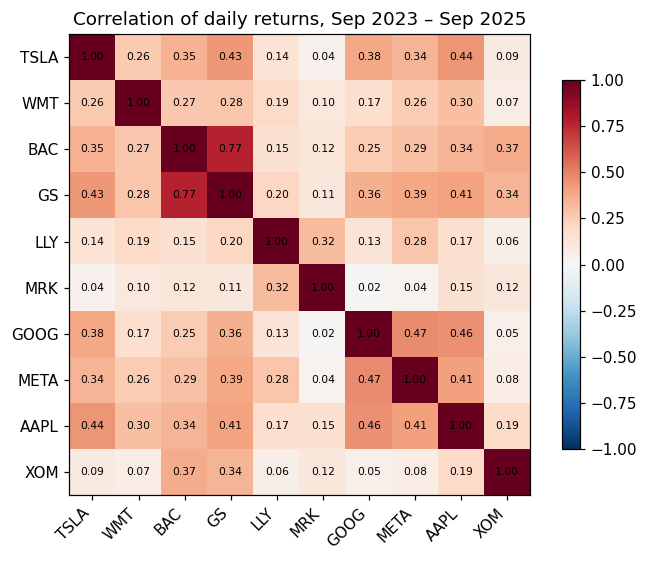

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create output directory if it doesn't exist
Path("figures").mkdir(parents=True, exist_ok=True)

corr = R_is[TICKERS].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(TICKERS)))
ax.set_xticklabels(TICKERS, rotation=45, ha="right")
ax.set_yticks(range(len(TICKERS)))
ax.set_yticklabels(TICKERS)

for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=7
        )

ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation of daily returns, Sep 2023 – Sep 2025")

plt.tight_layout()
plt.savefig("figures/fig0_asset_corr.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 1 – Standard mean-variance optimisation[cite: 3]

The "optimal" mean-variance portfolio is the **tangency (maximum Sharpe ratio) portfolio**: among all feasible portfolios it gives the highest excess return per unit of risk. We solve[cite: 3]

$$\max_{w} \frac{w^\top \mu - r_f}{\sqrt{w^\top \Sigma w}} \quad \text{s.t.} \quad \mathbf{1}^\top w = 1, \quad 0 \le w_i \le u$$

with a quadratic-programming solver (SLSQP). $u = 1$ in Step 1 (long-only), and $u = 0.15$ in Step 2. The brief states the client's limit as 15% in one sentence and 0.18 in the next, so we solve both caps and treat **15%** (the client's stated limit, which also satisfies an 18% limit) as the Step 2 portfolio carried into Parts 2 and 4.[cite: 3]

In [15]:
def port_stats(w, mu, S, rf_d=0.0):
    r = float(w @ mu) * ANN
    v = float(np.sqrt(w @ S @ w * ANN))
    return r, v, (r - rf_d*ANN) / v

def max_sharpe(mu, S, rf_d, ub=1.0, n_starts=20, seed=0):
    mu, S = np.asarray(mu), np.asarray(S); n = len(mu)
    cons = ({'type': 'eq', 'fun': lambda w: w.sum() - 1},)
    bnds = [(0, ub)] * n
    neg_sr = lambda w: -(w @ mu - rf_d) / np.sqrt(w @ S @ w)
    rng = np.random.default_rng(seed); best = None
    for k in range(n_starts):  # several starting points to be safe
        w0 = np.full(n, 1/n) if k == 0 else rng.dirichlet(np.ones(n))
        w0 = np.clip(w0, 0, ub); w0 /= w0.sum()
        res = minimize(neg_sr, w0, method='SLSQP', bounds=bnds, constraints=cons,
                       options={'ftol': 1e-12, 'maxiter': 1000})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    w = np.where(best.x < 1e-6, 0, best.x)
    return w / w.sum()

def min_var_for_target(mu, S, target, ub=1.0):
    mu, S = np.asarray(mu), np.asarray(S); n = len(mu)
    cons = ({'type': 'eq', 'fun': lambda w: w.sum() - 1},
            {'type': 'eq', 'fun': lambda w: w @ mu - target})
    res = minimize(lambda w: w @ S @ w, np.full(n, 1/n), method='SLSQP',
                   bounds=[(0, ub)]*n, constraints=cons, options={'ftol': 1e-14, 'maxiter': 1000})
    return res.x if res.success else None

def frontier(mu, S, ub=1.0, npts=60):
    mu_a, n = np.asarray(mu), len(mu)
    # feasible return range under the box constraint
    cons = ({'type': 'eq', 'fun': lambda w: w.sum() - 1},)
    gmv = minimize(lambda w: w @ np.asarray(S) @ w, np.full(n, 1/n), method='SLSQP',
                   bounds=[(0, ub)]*n, constraints=cons, options={'ftol': 1e-14}).x
    order = np.argsort(-mu_a); w_max = np.zeros(n); left = 1.0
    for i in order:  # greedy fill - max-return feasible portfolio
        w_max[i] = min(ub, left); left -= w_max[i]
        if left <= 1e-12: break
    out = []
    for t in np.linspace(gmv @ mu_a, w_max @ mu_a, npts):
        w = min_var_for_target(mu, S, t, ub)
        if w is not None:
            out.append((np.sqrt(w @ np.asarray(S) @ w * ANN), t * ANN))
    return np.array(out), gmv

## Step 1- Long-only tangency portoflio (wights sum to 1, no short sales )

In [16]:
w1 = max_sharpe(mu, S, rf_d, ub=1.0)
w2 = max_sharpe(mu, S, rf_d, ub=0.15)       # Step 2: client limit 15%
w2b = max_sharpe(mu, S, rf_d, ub=0.18)      # Step 2 (alternative reading): 18% cap

W = pd.DataFrame({'Step 1: long-only': w1, 'Step 2: cap 15%': w2, 'Step 2: cap 18%': w2b}, index=TICKERS)
stats = pd.DataFrame({c: port_stats(W[c].values, mu, S, rf_d) for c in W},
                     index=['Exp. return (ann.)', 'Volatility (ann.)', 'Sharpe ratio'])
print('Optimal weights'); display(W.round(4))
print('In-sample portfolio statistics'); display(stats.round(4))
print('Number of assets held:', (W > 1e-4).sum().to_dict())

Optimal weights


,Step 1: long-only,Step 2: cap 15%,Step 2: cap 18%
TSLA,0.0000,0.0163,0.0000
WMT,0.4369,0.1500,0.1800
BAC,0.0000,0.1500,0.1800
GS,0.3465,0.1500,0.1800
LLY,0.0000,0.1442,0.1000
MRK,0.0000,0.0000,0.0000
GOOG,0.0495,0.1500,0.1800
META,0.1671,0.1500,0.1800
AAPL,0.0000,0.0409,0.0000
XOM,0.0000,0.0485,0.0000


In-sample portfolio statistics


,Step 1: long-only,Step 2: cap 15%,Step 2: cap 18%
Exp. return (ann.),0.4084,0.3396,0.3717
Volatility (ann.),0.1920,0.1840,0.1907
Sharpe ratio,1.8647,1.5713,1.6854


Number of assets held: {'Step 1: long-only': 4, 'Step 2: cap 15%': 9, 'Step 2: cap 18%': 6}


Observations. Without a cap the optimiser puts 44% in WMT and 35% in GS, plus META and a little GOOG: the four stocks with the best historical risk/return and fairly low correlation with each other. The 15% cap forces the money into nine names, and the in-sample Sharpe ratio drops from 1.86 to 1.57. That drop is the "price" of the client's diversification rule, measured on the in-sample data. With an 18% cap the portfolio holds six names and sits in between (Sharpe 1.69)

## Step 2 – Maximum weight constraint

The weights for the 15% and 18% caps are in the table above. The bar chart compares the three allocations.

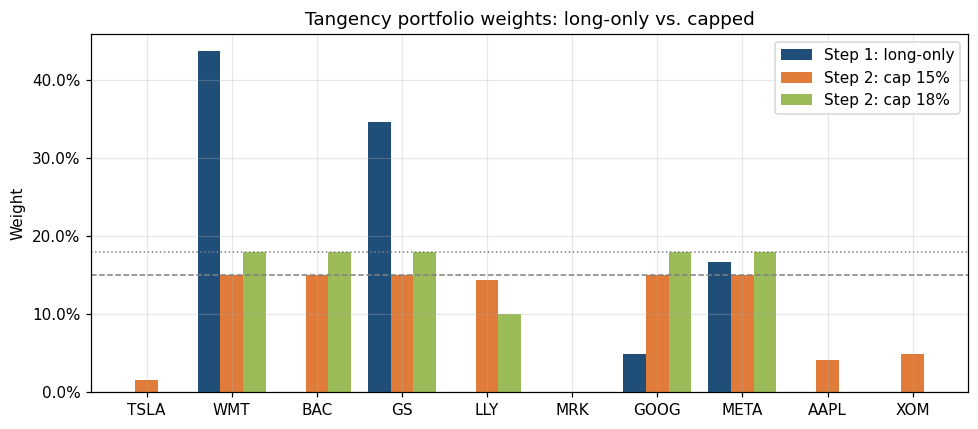

In [17]:
ax = W.plot.bar(figsize=(9, 4), width=0.8, color=['#1f4e79', '#e07b39', '#9bbb59'])
ax.axhline(0.15, ls='--', c='grey', lw=1); ax.axhline(0.18, ls=':', c='grey', lw=1)
ax.set_ylabel('Weight'); ax.set_title('Tangency portfolio weights: long-only vs. capped')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('figures/fig1_weights_part1.png', bbox_inches='tight'); plt.show()

#

## Step 3 - Efficient frontiers

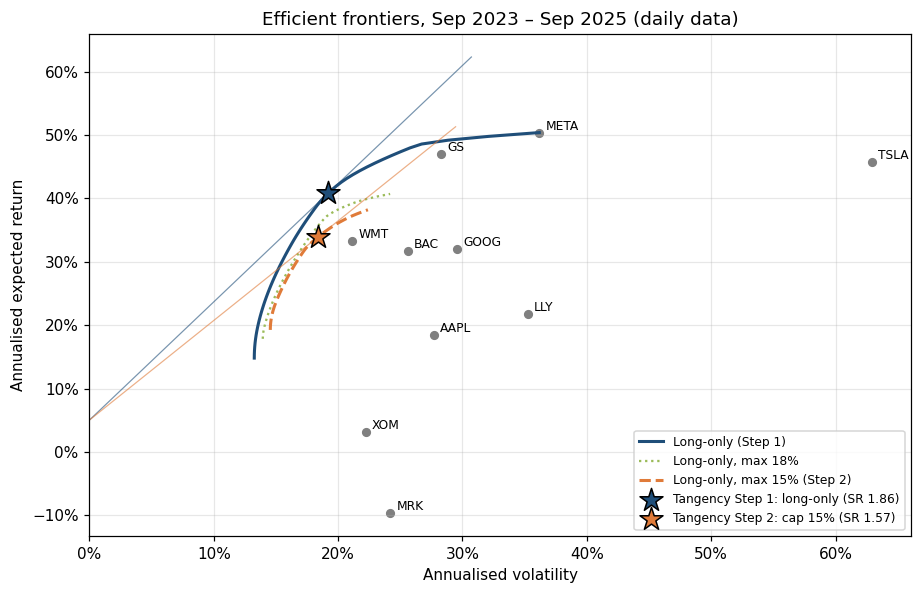

Long-only frontier: return range 14.81% to 50.39%, GMV vol 13.26%
Capped 15% frontier: return range 19.26% to 38.21%, GMV vol 14.55%
Capped 18% frontier: return range 17.86% to 40.71%, GMV vol 13.94%


In [18]:
fr1, gmv1 = frontier(mu, S, 1.0)
fr2, gmv2 = frontier(mu, S, 0.15)
fr3, gmv3 = frontier(mu, S, 0.18)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(fr1[:, 0], fr1[:, 1], c='#1f4e79', lw=2, label='Long-only (Step 1)')
ax.plot(fr3[:, 0], fr3[:, 1], c='#9bbb59', lw=1.5, ls=':', label='Long-only, max 18%')
ax.plot(fr2[:, 0], fr2[:, 1], c='#e07b39', lw=2, ls='--', label='Long-only, max 15% (Step 2)')
for c, col, m in [('Step 1: long-only', '#1f4e79', '*'), ('Step 2: cap 15%', '#e07b39', '*')]:
    r, v, s = stats[c]
    ax.scatter(v, r, marker=m, s=250, c=col, edgecolor='k', zorder=5, label=f'Tangency {c} (SR {s:.2f})')
    ax.plot([0, v*1.6], [rf_d*ANN, rf_d*ANN + s*v*1.6], c=col, lw=0.8, alpha=0.6)
vols = np.sqrt(np.diag(S)*ANN); ax.scatter(vols, mu*ANN, c='grey', s=25)
for t, x, y in zip(TICKERS, vols, mu*ANN): ax.annotate(t, (x, y), xytext=(4, 2), textcoords='offset points', fontsize=8)
ax.set_xlabel('Annualised volatility'); ax.set_ylabel('Annualised expected return')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(0, max(vols)*1.05); ax.set_title('Efficient frontiers, Sep 2023 – Sep 2025 (daily data)')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.savefig('figures/fig2_frontiers.png', bbox_inches='tight'); plt.show()

print(f'Long-only frontier: return range {fr1[0,1]:.2%} to {fr1[-1,1]:.2%}, GMV vol {fr1[0,0]:.2%}')
print(f'Capped 15% frontier: return range {fr2[0,1]:.2%} to {fr2[-1,1]:.2%}, GMV vol {fr2[0,0]:.2%}')
print(f'Capped 18% frontier: return range {fr3[0,1]:.2%} to {fr3[-1,1]:.2%}, GMV vol {fr3[0,0]:.2%}')

Observations. The capped frontier lies inside the long-only frontier and is much *shorter*: its maximum attainable return falls from 50.4% (100% in META) to 38.2%, because no single stock can exceed 15%. It also starts at a higher minimum-variance volatility (14.6% vs 13.3%), since the low-volatility names cannot be loaded up. The two curves are close only in the middle part, where the unconstrained frontier portfolios already respect the cap. So the tangency line is flatter, with a lower Sharpe ratio.

## Step 4 – Out-of-sample performance (1 Oct – 31 Dec 2025)

Each portfolio is bought at the 30 Sep 2025 close with the optimal weights and held without rebalancing (buy-and-hold) to 31 Dec 2025. Sharpe ratios are annualised from daily excess returns over the T-bill rate. Max drawdown is the largest peak-to-trough fall in portfolio value. For context we also show the S&P 500 and an equally weighted portfolio of the 10 stocks.

,Step 1: long-only,Step 2: cap 15%,Step 2: cap 18%,Equal weight (1/10),S&P 500
Cumulative return,0.0687,0.1309,0.1197,0.1247,0.0235
Ann. volatility,0.1471,0.1292,0.1373,0.1338,0.1262
Sharpe ratio (ann.),1.5104,3.4237,2.9452,3.1499,0.3871
Max drawdown,-0.0502,-0.0297,-0.0291,-0.0361,-0.0511


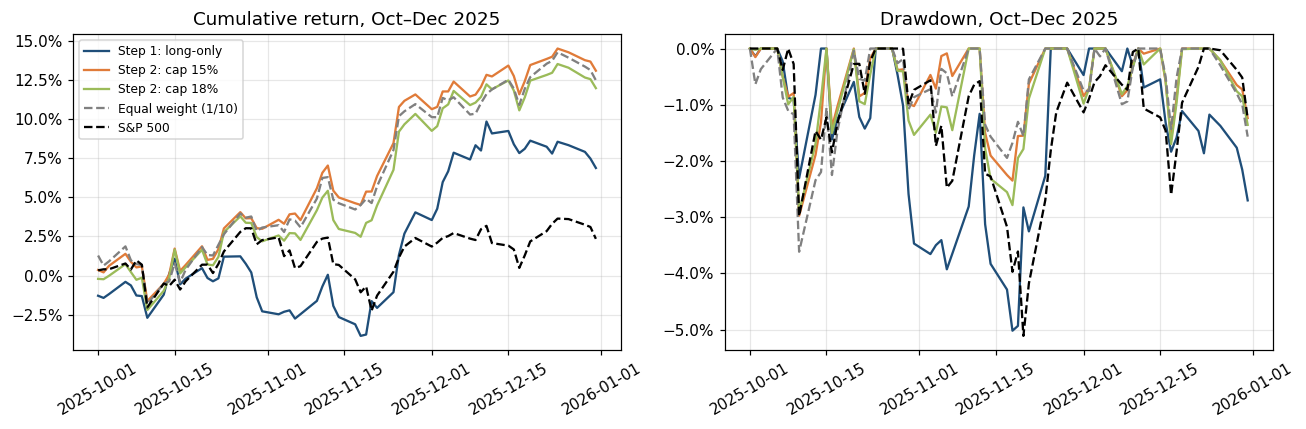

Out-of-sample stock returns (Oct–Dec 2025):


Ticker,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM
Return,0.0112,0.0810,0.0661,0.1038,0.4085,0.2541,0.2884,-0.1012,0.0677,0.0673


In [19]:
def buy_and_hold(weights, R):
    growth = (1 + R).cumprod()
    value = growth.mul(weights, axis=1).sum(axis=1)
    return value.pct_change().fillna(value.iloc[0] - 1)

def perf(r, rf_series):
    wealth = (1 + r).cumprod()
    ex = r - rf_series
    return pd.Series({'Cumulative return': wealth.iloc[-1] - 1,
                      'Ann. volatility': r.std() * np.sqrt(ANN),
                      'Sharpe ratio (ann.)': ex.mean() / ex.std() * np.sqrt(ANN),
                      'Max drawdown': (wealth / wealth.cummax() - 1).min()})

oos = {'Step 1: long-only': buy_and_hold(W['Step 1: long-only'], R_oos[TICKERS]),
       'Step 2: cap 15%': buy_and_hold(W['Step 2: cap 15%'], R_oos[TICKERS]),
       'Step 2: cap 18%': buy_and_hold(W['Step 2: cap 18%'], R_oos[TICKERS]),
       'Equal weight (1/10)': buy_and_hold(pd.Series(0.1, index=TICKERS), R_oos[TICKERS]),
       'S&P 500': R_oos['SPX']}
oos_perf = pd.DataFrame({k: perf(v, rf_oos) for k, v in oos.items()})
display(oos_perf.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (k, v), col in zip(oos.items(), ['#1f4e79', '#e07b39', '#9bbb59', 'grey', 'k']):
    w_ = (1 + v).cumprod(); ls = '--' if k in ('Equal weight (1/10)', 'S&P 500') else '-'
    axes[0].plot(w_.index, w_ - 1, label=k, c=col, ls=ls); axes[1].plot(w_.index, w_/w_.cummax() - 1, c=col, ls=ls)
axes[0].set_title('Cumulative return, Oct–Dec 2025'); axes[1].set_title('Drawdown, Oct–Dec 2025')
for a in axes:
    a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); a.tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('figures/fig3_oos.png', bbox_inches='tight'); plt.show()

print('Out-of-sample stock returns (Oct–Dec 2025):')
display(((1 + R_oos[TICKERS]).prod() - 1).to_frame('Return').T.round(4))

Observations. Out of sample the ranking flips. The capped portfolio returned 13.1% in the quarter (Sharpe 3.42, max drawdown -3.0%), against 6.9% for the unconstrained one (Sharpe 1.51, drawdown -5.0%). The S&P 500 returned 2.3%. The concentrated portfolio was hurt by META (-10%) and by holding no LLY (+41%) or MRK (+25%) and only 5% in GOOG (+29%). The cap gave better protection against estimation error in the historical means.

## Part 2 – Fama–French 5-factor style analysis of the Step 2 portfolio

$$R_{p,t} - R_{f,t} = \alpha + \beta_1(R_{m,t} - R_{f,t}) + \beta_2 SMB_t + \beta_3 HML_t + \beta_4 RMW_t + \beta_5 CMA_t + \varepsilon_t$$

The portfolio return series is the daily return of the Step 2 (15% cap) portfolio held at constant weights (rebalanced daily), which is the standard way to describe the style of a fixed allocation.

## Step 4 (Part 2) – The factors and their correlation matrix

Factor summary (training window)


,Ann. mean,Ann. vol
Mkt-RF,0.1702,0.1637
SMB,-0.0807,0.1239
HML,0.0241,0.1135
RMW,-0.0262,0.0846
CMA,-0.0545,0.0693


Factor correlation matrix (training window)


,Mkt-RF,SMB,HML,RMW,CMA
Mkt-RF,1.0000,0.2120,-0.2550,-0.3840,0.0250
SMB,0.2120,1.0000,0.3920,-0.4010,0.1540
HML,-0.2550,0.3920,1.0000,0.1860,0.1050
RMW,-0.3840,-0.4010,0.1860,1.0000,-0.1100
CMA,0.0250,0.1540,0.1050,-0.1100,1.0000


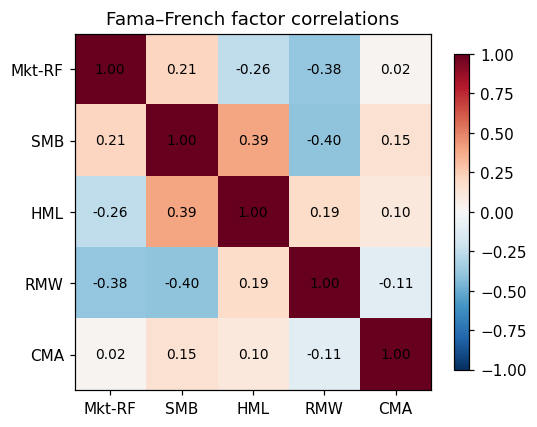

Variance inflation factors:
Mkt-RF   1.2800
SMB      1.7100
HML      1.5500
RMW      1.5100
CMA      1.0300


In [20]:
FACT = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
F_is, F_oos = ff.loc[IS_START:IS_END, FACT], ff.loc[OOS_START:OOS_END, FACT]
desc = pd.DataFrame({'Ann. mean': F_is.mean()*ANN, 'Ann. vol': F_is.std()*np.sqrt(ANN)})
print('Factor summary (training window)'); display(desc.round(4))
fcorr = F_is.corr()
print('Factor correlation matrix (training window)'); display(fcorr.round(3))

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(fcorr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(FACT); ax.set_yticks(range(5)); ax.set_yticklabels(FACT)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{fcorr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title('Fama–French factor correlations')
plt.tight_layout(); plt.savefig('figures/fig4_factor_corr.png', bbox_inches='tight'); plt.show()

X_ = sm.add_constant(F_is)
vif = pd.Series([1/(1 - sm.OLS(F_is[c], sm.add_constant(F_is.drop(columns=c))).fit().rsquared) for c in FACT], index=FACT)
print('Variance inflation factors:'); print(vif.round(2).to_string())

## Step 5 – OLS and robust regression, training/testing split

**Data split.** The data is split by time, not at random, because shuffling a time series lets future information into the fit:
* **Training set:** 1 Sep 2023 – 30 Sep 2025 (the same window used to choose the portfolio weights).
* **Testing set:** 1 Oct 2025 – 31 Dec 2025 (the out-of-sample quarter used in Part 1, Step 4).

The coefficients are estimated only on the training set and then used to predict the test-set excess returns from the realised factor returns.

**Models.** (i) OLS with Newey–West (HAC, 5 lags) standard errors, which stay valid under heteroskedasticity and autocorrelation in daily returns; (ii) a robust M-estimator with Huber's loss (tuning constant 1.345), which down-weights large residuals such as earnings-day jumps so that a few extreme days cannot dominate the betas. As a further check we also re-fit both models on a chronological 80/20 split *inside* the training window.

In [22]:
wp = W['Step 2: cap 15%']
rp = R_is[TICKERS] @ wp
y_is = rp - rf_is
y_oos = (R_oos[TICKERS] @ wp) - rf_oos

Xtr, Xte = sm.add_constant(F_is), sm.add_constant(F_oos)
ols = sm.OLS(y_is, Xtr).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
rlm = sm.RLM(y_is, Xtr, M=sm.robust.norms.HuberT(t=1.345)).fit()

def r2(y, yhat):
    return 1 - ((y - yhat)**2).sum() / ((y - y.mean())**2).sum()

coef = pd.DataFrame({'OLS coef': ols.params, 'OLS t (HAC)': ols.tvalues, 'OLS p': ols.pvalues,
                     'Huber coef': rlm.params, 'Huber t': rlm.tvalues, 'Huber p': rlm.pvalues})
coef.loc['const', ['OLS coef', 'Huber coef']] *= ANN     # report alpha annualised
coef = coef.rename(index={'const': 'Alpha (ann.)'})
display(coef.round(4))

fit = pd.DataFrame({
    'Train R2': [ols.rsquared, r2(y_is, rlm.fittedvalues)],
    'Test R2': [r2(y_oos, ols.predict(Xte)), r2(y_oos, rlm.predict(Xte))],
    'Train RMSE (%)': [np.sqrt(np.mean(ols.resid**2))*100, np.sqrt(np.mean((y_is - rlm.fittedvalues)**2))*100],
    'Test RMSE (%)': [np.sqrt(np.mean((y_oos - ols.predict(Xte))**2))*100, np.sqrt(np.mean((y_oos - rlm.predict(Xte))**2))*100],
    'Test corr(actual, fitted)': [np.corrcoef(y_oos, ols.predict(Xte))[0, 1], np.corrcoef(y_oos, rlm.predict(Xte))[0, 1]]},
    index=['OLS', 'Huber robust'])
display(fit.round(4))
print(f'Train obs: {len(y_is)}, Test obs: {len(y_oos)}; share of days down-weighted by Huber (weight<1): {(rlm.weights < 1).mean():.1%}')

,OLS coef,OLS t (HAC),OLS p,Huber coef,Huber t,Huber p
Alpha (ann.),0.0728,1.3758,0.1689,0.0862,1.7319,0.0833
Mkt-RF,1.0464,40.4256,0.0000,1.0409,48.3873,0.0000
SMB,-0.1566,-3.8586,0.0001,-0.1499,-4.5567,0.0000
HML,0.2015,4.4643,0.0000,0.1901,5.5719,0.0000
RMW,-0.0952,-1.6364,0.1017,-0.0687,-1.5207,0.1283
CMA,-0.3350,-4.5369,0.0000,-0.2755,-6.0303,0.0000


,Train R2,Test R2,Train RMSE (%),Test RMSE (%),"Test corr(actual, fitted)"
OLS,0.8194,0.4748,0.4923,0.5780,0.7867
Huber robust,0.8188,0.5132,0.4931,0.5565,0.7921


Train obs: 521, Test obs: 64; share of days down-weighted by Huber (weight<1): 21.7%


80/20 split: train 2023-09-01 to 2025-04-30 (416 obs), test 2025-05-01 to 2025-09-30 (105 obs)


,OLS,Huber
Alpha (daily),0.0003,0.0003
Mkt-RF,1.0418,1.0330
SMB,-0.1666,-0.1582
HML,0.2045,0.1927
RMW,-0.1056,-0.0907
CMA,-0.3420,-0.3003
Test R2,0.6803,0.6806


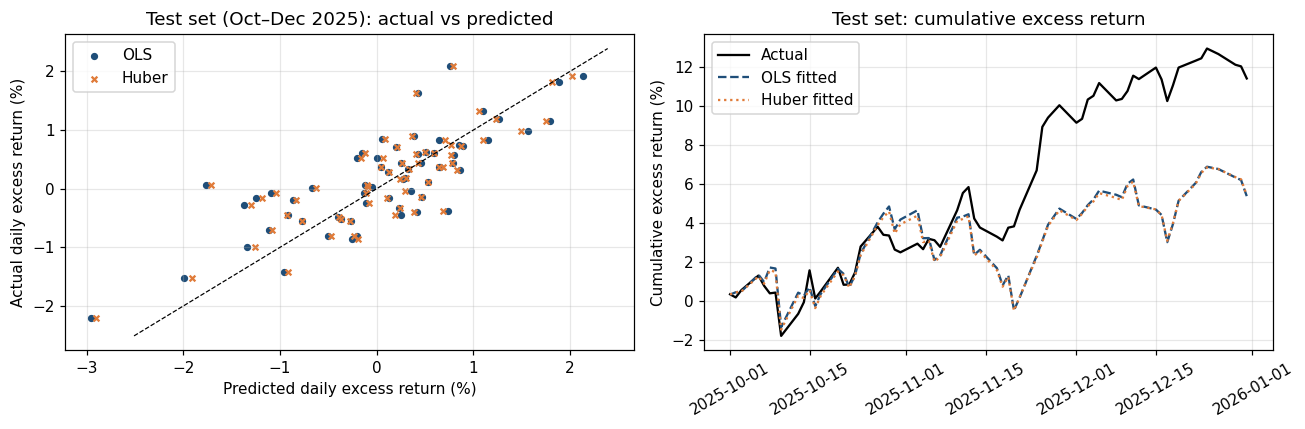

In [23]:
# robustness: chronological 80/20 split inside the training window
cut = int(len(y_is) * 0.8)
ya, yb, Xa, Xb = y_is.iloc[:cut], y_is.iloc[cut:], Xtr.iloc[:cut], Xtr.iloc[cut:]
o2 = sm.OLS(ya, Xa).fit(cov_type='HAC', cov_kwds={'maxlags': 5}); h2 = sm.RLM(ya, Xa, M=sm.robust.norms.HuberT()).fit()
print(f'80/20 split: train {ya.index[0].date()} to {ya.index[-1].date()} ({len(ya)} obs), test {yb.index[0].date()} to {yb.index[-1].date()} ({len(yb)} obs)')
alt = pd.DataFrame({'OLS': o2.params, 'Huber': h2.params}).rename(index={'const': 'Alpha (daily)'})
alt.loc['Test R2'] = [r2(yb, o2.predict(Xb)), r2(yb, h2.predict(Xb))]
display(alt.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ols.predict(Xte)*100, y_oos*100, s=14, c='#1f4e79', label='OLS')
axes[0].scatter(rlm.predict(Xte)*100, y_oos*100, s=14, c='#e07b39', marker='x', label='Huber')
lim = [y_oos.min()*100 - 0.3, y_oos.max()*100 + 0.3]; axes[0].plot(lim, lim, 'k--', lw=0.8)
axes[0].set_xlabel('Predicted daily excess return (%)'); axes[0].set_ylabel('Actual daily excess return (%)')
axes[0].set_title('Test set (Oct–Dec 2025): actual vs predicted'); axes[0].legend()
axes[1].plot(((1 + y_oos).cumprod() - 1)*100, c='k', label='Actual')
axes[1].plot(((1 + ols.predict(Xte)).cumprod() - 1)*100, c='#1f4e79', ls='--', label='OLS fitted')
axes[1].plot(((1 + rlm.predict(Xte)).cumprod() - 1)*100, c='#e07b39', ls=':', label='Huber fitted')
axes[1].set_ylabel('Cumulative excess return (%)'); axes[1].set_title('Test set: cumulative excess return'); axes[1].legend(); axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('figures/fig5_ff_test.png', bbox_inches='tight'); plt.show()

## Step 6 – Which factors explain the portfolio?

The written interpretation is in the report. In short, we use the significance and size of each beta, and how stable it is across OLS and Huber, to say which style tilts the portfolio has. The contribution table below splits the portfolio's average daily excess return into the part earned from each factor ($\beta \times \text{average factor return}$) and the unexplained alpha.

In [25]:
contrib = pd.DataFrame({'Beta (OLS)': ols.params[FACT], 'Avg factor ret (ann.)': F_is.mean()*ANN})
contrib['Contribution (ann.)'] = contrib['Beta (OLS)'] * contrib['Avg factor ret (ann.)']
contrib.loc['Alpha'] = [np.nan, np.nan, ols.params['const']*ANN]
contrib.loc['Total = avg excess return'] = [np.nan, np.nan, contrib['Contribution (ann.)'].sum()]
display(contrib.round(4))
print(f'Check – realised average excess return (ann.): {y_is.mean()*ANN:.4f}')

,Beta (OLS),Avg factor ret (ann.),Contribution (ann.)
Mkt-RF,1.0464,0.1702,0.1781
SMB,-0.1566,-0.0807,0.0126
HML,0.2015,0.0241,0.0049
RMW,-0.0952,-0.0262,0.0025
CMA,-0.3350,-0.0545,0.0182
Alpha,NaN,NaN,0.0728
Total = avg excess return,NaN,NaN,0.2892


Check – realised average excess return (ann.): 0.2892


Observations. The market beta is about 1.05 and dominates ($t \approx 40$). The portfolio also has a significant **large-cap** tilt (negative SMB), a **value** tilt (positive HML, from the banks and Walmart's defensive profile), and an **aggressive-investment** tilt (negative CMA, from the high-capex AI and growth names). Profitability (RMW) is not significant at 5%. OLS and Huber give almost the same betas, so the results are not driven by outliers; Huber shrinks CMA and RMW a little. The intercept (7–9% p.a.) is not significant at 5%. On the test quarter the model explains about half the daily variance ($R^2$ 0.47 OLS / 0.51 Huber)

## Part 3 – Can simulation replace optimisation?

We choose five stocks from five different sectors so that the problem is not trivial and the assets are not near-duplicates: **GOOG** (communication services / technology), **LLY** (health care), **WMT** (consumer staples), **GS** (financials) and **XOM** (energy). Same estimation window and same risk-free rate as Part 1.

**Simulation method.** We draw random weight vectors **uniformly on the simplex** (Dirichlet distribution with all parameters equal to 1), so every long-only, fully invested portfolio is equally likely. This avoids the bias of the common "draw uniforms and divide by the sum" approach, which crowds portfolios towards equal weights. For each sample size $N$ we keep the simulated portfolio with the highest Sharpe ratio and compare its weights with the optimiser's. Because one run is down to luck, each $N$ is repeated 30 times with different seeds.

In [26]:
SEL = ['GOOG', 'LLY', 'WMT', 'GS', 'XOM']
mu5, S5 = mu[SEL].values, S.loc[SEL, SEL].values
w7_opt = max_sharpe(mu5, S5, rf_d, ub=1.0)
w8_opt = max_sharpe(mu5, S5, rf_d, ub=0.30)
opt5 = pd.DataFrame({'Step 7 (no cap)': w7_opt, 'Step 8 (cap 30%)': w8_opt}, index=SEL)
display(opt5.round(4))
display(pd.DataFrame({c: port_stats(opt5[c].values, mu5, S5, rf_d) for c in opt5},
                     index=['Exp. return (ann.)', 'Volatility (ann.)', 'Sharpe ratio']).round(4))

def sharpe_batch(Wm, mu, S, rf_d):
    ret = Wm @ mu; vol = np.sqrt(np.einsum('ij,jk,ik->i', Wm, S, Wm))
    return (ret - rf_d) / vol * np.sqrt(ANN)

def simulate_best(N, mu, S, rf_d, seed, cap=None, batch=200_000):
    # returns best weights among N *feasible* random portfolios, plus number of raw draws used
    rng = np.random.default_rng(seed); n = len(mu); best_w, best_s, kept, drawn = None, -np.inf, 0, 0
    while kept < N:
        m = min(batch, int((N - kept) / (0.05 if cap else 1)) + 10)
        Wm = rng.dirichlet(np.ones(n), size=m); drawn += m
        if cap is not None:
            Wm = Wm[Wm.max(axis=1) <= cap]       # rejection step for the box constraint
        Wm = Wm[:N - kept]; kept += len(Wm)
        if len(Wm):
            s = sharpe_batch(Wm, mu, S, rf_d); i = s.argmax()
            if s[i] > best_s: best_s, best_w = s[i], Wm[i]
    return best_w, best_s, drawn

,Step 7 (no cap),Step 8 (cap 30%)
GOOG,0.1254,0.2907
LLY,0.0060,0.1093
WMT,0.4753,0.3000
GS,0.3933,0.3000
XOM,0.0000,0.0000


,Step 7 (no cap),Step 8 (cap 30%)
Exp. return (ann.),0.3846,0.3578
Volatility (ann.),0.1858,0.1826
Sharpe ratio,1.7983,1.6839


## Step 7 – Long-only, fully invested (5 assets): optimisation vs simulation

In [27]:
Ns = [100, 500, 1_000, 5_000, 10_000, 50_000, 100_000, 500_000, 1_000_000]
sr7 = port_stats(w7_opt, mu5, S5, rf_d)[2]

def convergence(w_opt, sr_opt, cap=None):
    rows = []
    for N in Ns:
        reps = 30 if N <= 100_000 else 10        # fewer repetitions for the very large N
        errs, gaps, draws = [], [], []
        for s in range(reps):
            w, srs, d = simulate_best(N, mu5, S5, rf_d, seed=1000*s + 7, cap=cap)
            errs.append(np.abs(w - w_opt).max()); gaps.append(sr_opt - srs); draws.append(d)
        rows.append({'N feasible portfolios': N, 'runs': reps, 'avg raw draws': np.mean(draws),
                     'mean max |w_sim - w_opt|': np.mean(errs), '95th pct max |dw|': np.percentile(errs, 95),
                     'mean Sharpe gap': np.mean(gaps), 'share of runs within 1pp': np.mean(np.array(errs) < 0.01)})
    return pd.DataFrame(rows).set_index('N feasible portfolios')

conv7 = convergence(w7_opt, sr7)
display(conv7.drop(columns='avg raw draws').round(4))

w7_sim, s7_sim, _ = simulate_best(1_000_000, mu5, S5, rf_d, seed=42)
display(pd.DataFrame({'Optimisation': w7_opt, 'Simulation (N=1,000,000)': w7_sim,
                      'Difference': w7_sim - w7_opt}, index=SEL).round(4))
print(f'Sharpe: optimiser {sr7:.4f} vs best simulated {s7_sim:.4f}')

,runs,mean max |w_sim - w_opt|,95th pct max |dw|,mean Sharpe gap,share of runs within 1pp
N feasible portfolios,,,,,
100,30,0.1318,0.2025,0.0760,0.0000
500,30,0.0942,0.1494,0.0373,0.0000
1000,30,0.0708,0.1191,0.0240,0.0000
5000,30,0.0483,0.0876,0.0123,0.0000
10000,30,0.0431,0.0715,0.0092,0.0333
50000,30,0.0293,0.0556,0.0044,0.0333
100000,30,0.0264,0.0393,0.0033,0.0333
500000,10,0.0247,0.0340,0.0020,0.0000
1000000,10,0.0181,0.0280,0.0015,0.1000


,Optimisation,"Simulation (N=1,000,000)",Difference
GOOG,0.1254,0.1053,-0.0201
LLY,0.0060,0.0126,0.0066
WMT,0.4753,0.4881,0.0128
GS,0.3933,0.3933,-0.0000
XOM,0.0000,0.0007,0.0007


Sharpe: optimiser 1.7983 vs best simulated 1.7968


Observations. The Sharpe ratio of the best simulated portfolio gets close very quickly (within 0.01 by about 10,000 draws), but the *weights* converge slowly. The Sharpe surface is flat near the optimum, so quite different weights give almost the same Sharpe. Getting every weight within about 2 percentage points of the optimiser takes on the order of **one million** portfolios, and even then only some runs land within 1 pp.

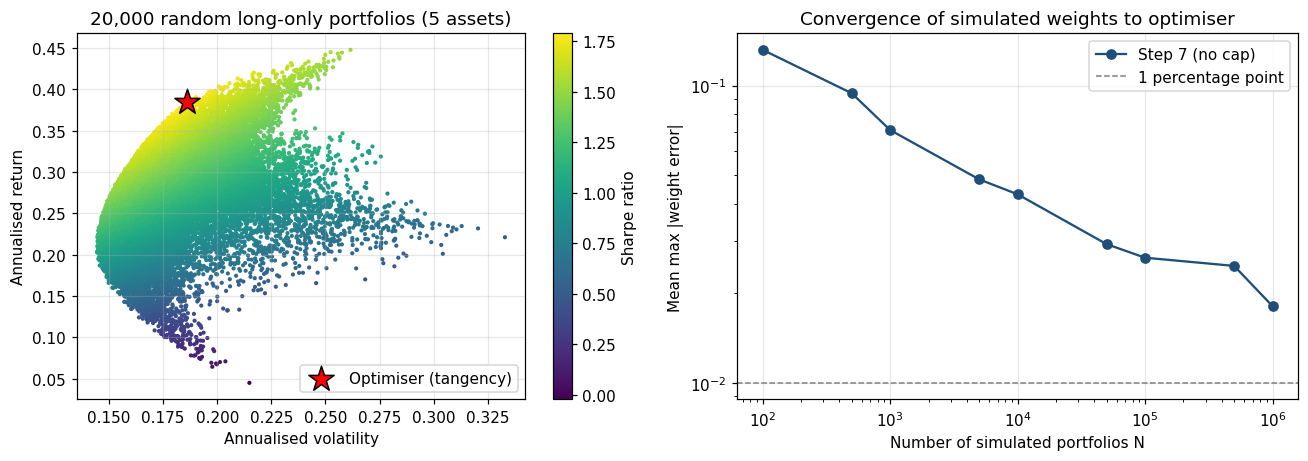

In [28]:
rng = np.random.default_rng(1); cloud = rng.dirichlet(np.ones(5), 20_000)
cr, cv = cloud @ mu5 * ANN, np.sqrt(np.einsum('ij,jk,ik->i', cloud, S5, cloud) * ANN)
cs = (cr - rf_d*ANN) / cv
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sc = axes[0].scatter(cv, cr, c=cs, s=3, cmap='viridis'); fig.colorbar(sc, ax=axes[0], label='Sharpe ratio')
r7, v7, _ = port_stats(w7_opt, mu5, S5, rf_d); axes[0].scatter(v7, r7, marker='*', s=300, c='red', edgecolor='k', label='Optimiser (tangency)')
axes[0].set_xlabel('Annualised volatility'); axes[0].set_ylabel('Annualised return'); axes[0].legend(loc='lower right')
axes[0].set_title('20,000 random long-only portfolios (5 assets)')
axes[1].loglog(conv7.index, conv7['mean max |w_sim - w_opt|'], 'o-', c='#1f4e79', label='Step 7 (no cap)')
axes[1].axhline(0.01, c='grey', ls='--', lw=1, label='1 percentage point')
axes[1].set_xlabel('Number of simulated portfolios N'); axes[1].set_ylabel('Mean max |weight error|')
axes[1].set_title('Convergence of simulated weights to optimiser'); axes[1].legend()
plt.tight_layout(); plt.savefig('figures/fig6_sim_step7.png', bbox_inches='tight'); plt.show()

## Step 8 – Adding the 30% cap

With the cap, a random simplex draw is only admissible if *every* weight is $\le 0.30$. For a uniform draw on the 5-asset simplex the probability of this is

$$P(\max_i w_i \le c) = \sum_{k=0}^{n} (-1)^k \binom{n}{k} (1 - kc)_+^{n-1} = 1 - 5(0.7)^4 + 10(0.4)^4 - 10(0.1)^4 \approx 5.45\%$$

so about 18 draws are needed for every feasible portfolio. We therefore simulate by **rejection sampling**: draw uniformly on the simplex and keep only draws that satisfy all five box constraints. The kept draws are uniform on the capped region, so the comparison with Step 7 is like-for-like. $N$ below counts *feasible* portfolios.

Acceptance probability: theory 5.4500%, empirical 5.4932%


,runs,avg raw draws,mean max |w_sim - w_opt|,95th pct max |dw|,mean Sharpe gap,share of runs within 1pp
N feasible portfolios,,,,,,
100,30,2036.0000,0.0887,0.1327,0.0739,0.0000
500,30,10010.0000,0.0598,0.1011,0.0381,0.0000
1000,30,20010.0000,0.0525,0.0939,0.0281,0.0000
5000,30,100010.0000,0.0389,0.0622,0.0172,0.0000
10000,30,200000.0000,0.0330,0.0551,0.0142,0.0000
50000,30,928540.0000,0.0204,0.0376,0.0074,0.1333
100000,30,1839194.6667,0.0155,0.0309,0.0056,0.3333
500000,10,9190413.0000,0.0115,0.0212,0.0032,0.5000
1000000,10,18356586.0000,0.0144,0.0253,0.0028,0.3000


,Optimisation,"Simulation (N=1,000,000 feasible)",Difference
GOOG,0.2907,0.2771,-0.0136
LLY,0.1093,0.1201,0.0108
WMT,0.3000,0.2994,-0.0006
GS,0.3000,0.2967,-0.0033
XOM,0.0000,0.0067,0.0067


Sharpe: optimiser 1.6839 vs best simulated 1.6797; raw draws needed: 18,356,430


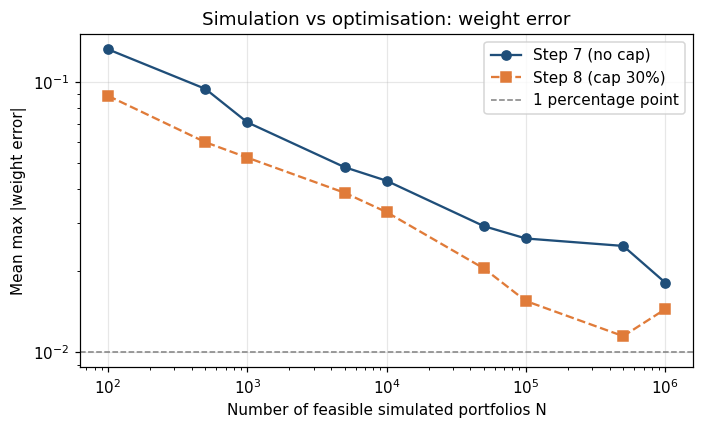

In [29]:
from math import comb
p_acc = sum((-1)**k * comb(5, k) * max(1 - k*0.3, 0)**4 for k in range(6))
emp = (np.random.default_rng(3).dirichlet(np.ones(5), 1_000_000).max(axis=1) <= 0.3).mean()
print(f'Acceptance probability: theory {p_acc:.4%}, empirical {emp:.4%}')

sr8 = port_stats(w8_opt, mu5, S5, rf_d)[2]
conv8 = convergence(w8_opt, sr8, cap=0.30)
display(conv8.round(4))

w8_sim, s8_sim, d8 = simulate_best(1_000_000, mu5, S5, rf_d, seed=42, cap=0.30)
display(pd.DataFrame({'Optimisation': w8_opt, 'Simulation (N=1,000,000 feasible)': w8_sim,
                      'Difference': w8_sim - w8_opt}, index=SEL).round(4))
print(f'Sharpe: optimiser {sr8:.4f} vs best simulated {s8_sim:.4f}; raw draws needed: {d8:,.0f}')

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(conv7.index, conv7['mean max |w_sim - w_opt|'], 'o-', c='#1f4e79', label='Step 7 (no cap)')
ax.loglog(conv8.index, conv8['mean max |w_sim - w_opt|'], 's--', c='#e07b39', label='Step 8 (cap 30%)')
ax.axhline(0.01, c='grey', ls='--', lw=1, label='1 percentage point')
ax.set_xlabel('Number of feasible simulated portfolios N'); ax.set_ylabel('Mean max |weight error|')
ax.set_title('Simulation vs optimisation: weight error'); ax.legend()
plt.tight_layout(); plt.savefig('figures/fig7_sim_convergence.png', bbox_inches='tight'); plt.show()

Observations. The 30% cap binds for WMT and GS, so the weight moves from them to GOOG (29%) and LLY (11%). In terms of feasible portfolios, the capped problem converges at a similar or slightly faster rate, because the feasible region is smaller. But every feasible portfolio costs about 18 raw draws, so reaching roughly 1–1.5 pp accuracy takes about 500,000–1,000,000 feasible portfolios, i.e. **10–20 million random draws**. The optimiser solves the same problem exactly in a fraction of a second.

## Part 4 – Black–Litterman

## Step 9(a) – Market portfolio: synthetic composite (10 stocks + "rest of the S&P 500")

The market portfolio is the S&P 500. On 30 Sep 2025 our ten stocks had the index weights shown below (only Alphabet's class C line, GOOG, is counted, since that is the share class in our universe). An 11th asset, **REST**, stands for the remaining ~490 constituents. Its weight is $1 - \sum_{i=1}^{10} w_i$, and its daily return is backed out from the index:

$$r_{REST,t} = \frac{r_{SPX,t} - \sum_{i=1}^{10} w_i r_{i,t}}{w_{REST}}$$

The covariance matrix is then estimated on all **11** assets. Note that we hold the 30 Sep 2025 weights fixed over the window, which is an approximation since index weights drift.


In [33]:
import pandas as pd
from pathlib import Path

sp500_history = pd.read_csv(
    "data/sp500_historical_components.csv",
    parse_dates=["date"]
)

target_date = pd.Timestamp("2025-09-30")

# Use the latest available snapshot on or before the target date
available = sp500_history.loc[
    sp500_history["date"] <= target_date
].sort_values("date")

if available.empty:
    raise ValueError("No constituent snapshot exists on or before the target date.")

snapshot = available.iloc[-1]
snapshot_date = snapshot["date"]
constituents = [
    ticker.strip()
    for ticker in snapshot["tickers"].split(",")
    if ticker.strip()
]

print("Target date:", target_date.date())
print("Snapshot date:", snapshot_date.date())
print("Number of constituents:", len(constituents))

# Save the constituents for later use
pd.DataFrame({"ticker": constituents}).to_csv(
    "data/sp500_constituents_20250930.csv", index=False
)

# Check your 10 portfolio stocks
TICKERS = [
    "TSLA", "WMT", "BAC", "GS", "LLY",
    "MRK", "GOOG", "META", "AAPL", "XOM"
]

membership_check = pd.DataFrame({
    "ticker": TICKERS,
    "in_snapshot": [ticker in constituents for ticker in TICKERS]
})

display(membership_check)

Target date: 2025-09-30
Snapshot date: 2025-09-22
Number of constituents: 503


,ticker,in_snapshot
0,TSLA,True
1,WMT,True
2,BAC,True
3,GS,True
4,LLY,True
5,MRK,True
6,GOOG,True
7,META,True
8,AAPL,True
9,XOM,True


In [36]:
spw = pd.read_csv('data/sp500_weights.csv')
spw['weight'] = spw['Weight_Pct'] / 100          # CSV stores percent; convert to fraction
spw['weight'] /= spw['weight'].sum()             # renormalise (CSV sums to 100.03% from rounding)

w_mkt10 = spw.set_index('Symbol').loc[TICKERS, 'weight']
w_rest = 1 - w_mkt10.sum()
ASSETS = TICKERS + ['REST']
w_mkt = pd.concat([w_mkt10, pd.Series({'REST': w_rest})])
print(f'S&P 500 constituents in weights file: {len(spw)}; weights sum to {spw.weight.sum():.6f}')
display(w_mkt.to_frame('Market weight').T.round(4))

R11 = R_is[TICKERS].copy()
R11['REST'] = (R_is['SPX'] - R_is[TICKERS] @ w_mkt10) / w_rest
S11 = R11.cov()       # 11 x 11 daily covariance
print('Check: market variance from 11-asset covariance vs S&P 500 variance (ann.):',
      f'{w_mkt @ S11 @ w_mkt * ANN:.6f} vs {R_is["SPX"].var() * ANN:.6f}')

mkt_ex = R_is['SPX'] - rf_is
mkt_sr = mkt_ex.mean() / mkt_ex.std() * np.sqrt(ANN)
mkt_var = w_mkt @ S11 @ w_mkt
delta = (mkt_ex.mean()) / mkt_var       # risk aversion = (E[Rm]-Rf)/sigma_m^2
print(f'S&P 500 in-sample: excess return {mkt_ex.mean()*ANN:.2%} p.a., volatility {np.sqrt(mkt_var*ANN):.2%}, Sharpe ratio {mkt_sr:.3f}')
print(f'Implied risk-aversion coefficient delta = SR / sigma = {delta:.3f}')

S&P 500 constituents in weights file: 503; weights sum to 1.000000


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST
Market weight,0.0219,0.0080,0.0063,0.0043,0.0102,0.0035,0.0201,0.0284,0.0665,0.0086,0.8222


Check: market variance from 11-asset covariance vs S&P 500 variance (ann.): 0.024955 vs 0.024955
S&P 500 in-sample: excess return 15.29% p.a., volatility 15.80%, Sharpe ratio 0.968
Implied risk-aversion coefficient delta = SR / sigma = 6.128


In [37]:
Pi = delta * S11.values @ w_mkt.values        # implied equilibrium excess returns (daily)
prior = pd.DataFrame({'Market weight': w_mkt, 'Implied excess return Pi (ann.)': Pi*ANN,
                      'Historical excess return (ann.)': (R11.mean() - rf_d)*ANN}, index=ASSETS)
display(prior.round(4))
print(f'Check: w_mkt . Pi (ann.) = {w_mkt.values @ Pi * ANN:.4f} = market excess return')

,Market weight,Implied excess return Pi (ann.),Historical excess return (ann.)
TSLA,0.0219,0.3554,0.4077
WMT,0.0080,0.0823,0.2829
BAC,0.0063,0.1514,0.2668
GS,0.0043,0.2010,0.4191
LLY,0.0102,0.1190,0.1666
MRK,0.0035,0.0474,-0.1472
GOOG,0.0201,0.1717,0.2705
META,0.0284,0.2251,0.4535
AAPL,0.0665,0.1834,0.1347
XOM,0.0086,0.0636,-0.0189


Check: w_mkt . Pi (ann.) = 0.1529 = market excess return


Comment. The implied returns are much more even than the historical ones: MRK and XOM get positive equilibrium premia (4.7% and 6.4%), while the very high historical returns of META, GS and WMT are pulled down towards what their risk justifies. The risk-aversion coefficient (6.1) is higher than the textbook 2.5–3 because the S&P 500 Sharpe ratio over Sep 2023 – Sep 2025 was unusually high (0.97).

## Step 9(b) – Choice of $\tau$

$\tau$ scales the uncertainty of the prior mean: $\Pi \sim N(\mu, \tau \Sigma)$. If the mean is estimated from $T$ independent observations, the standard error of the mean has covariance $\Sigma / T$, so $\mathbf{\tau = 1/T}$ is the natural choice and it is automatically consistent with the data frequency: with $T$ daily observations, $\tau \Sigma$ is the variance of the estimated *daily* mean. Using a value such as 0.05 (popular with monthly data) on daily data would make the prior far too vague. We keep all inputs in daily units and annualise only for display

In [38]:
T = len(R11)
tau = 1 / T
print(f'T = {T} daily observations -> tau = 1/T = {tau:.5f}')

T = 521 daily observations -> tau = 1/T = 0.00192


## Step 9(c) – Views: P, Q and $\Omega$

Our views as of 30 Sep 2025 (annual excess returns, converted to daily units for the model):[cite: 19]

| # | View | Type | Q (ann.) | Confidence |
| :--- | :--- | :--- | :--- | :--- |
| 1 | **LLY outperforms MRK by 8%**: Lilly's GLP-1 franchise (Mounjaro/Zepbound) keeps growing while Merck faces the Keytruda patent cliff from 2028 | relative | 8% | high |
| 2 | **XOM earns no premium over cash**: OPEC+ is unwinding production cuts and Brent is in the mid-$60s | absolute | 0% | medium |
| 3 | **GOOG outperforms META by 5%**: the Sept-2025 search antitrust remedy was milder than feared, and Google Cloud/Gemini monetise AI while Meta's capex keeps rising | relative | 5% | medium |
| 4 | **Banks (½ BAC + ½ GS) outperform the rest of the market by 3%**: a steeper yield curve, lighter capital rules and a pick-up in M&A/IPO activity | relative | 3% | low |

$\mathbf{\Omega}$ **(view uncertainty)**. We start from He and Litterman's choice $\Omega_{kk} = (P \tau \Sigma P^\top)_{kk}$, which makes each view as uncertain as the prior for that combination of assets, and scale it by a confidence multiplier $c_k$: 0.5 for high confidence (half the variance), 1 for medium, and 2 for low. $\Omega$ is diagonal, i.e. the views are independent.

In [39]:
P = pd.DataFrame(0.0, index=['V1: LLY - MRK', 'V2: XOM', 'V3: GOOG - META', 'V4: Banks - REST'], columns=ASSETS)
P.loc['V1: LLY - MRK', ['LLY', 'MRK']] = [1, -1]
P.loc['V2: XOM', 'XOM'] = 1
P.loc['V3: GOOG - META', ['GOOG', 'META']] = [1, -1]
P.loc['V4: Banks - REST', ['BAC', 'GS', 'REST']] = [0.5, 0.5, -1]
Q_ann = np.array([0.08, 0.00, 0.05, 0.03])
Q = Q_ann / ANN
conf = np.array([0.5, 1.0, 1.0, 2.0])
Pm, Sm = P.values, S11.values
Omega = np.diag(conf * np.diag(Pm @ (tau * Sm) @ Pm.T))

print('P matrix'); display(P.round(2))
vt = pd.DataFrame({'Q (ann.)': Q_ann, 'Prior P.Pi (ann.)': Pm @ Pi * ANN, 'Confidence multiplier': conf,
                   'Omega (daily, x 1e5)': np.diag(Omega)*1e5, 'View st.dev (ann.)': np.sqrt(np.diag(Omega)) * ANN}, index=P.index)
display(vt)

P matrix


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST
V1: LLY - MRK,0.0000,0.0000,0.0000,0.0000,1.0000,-1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
V2: XOM,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
V3: GOOG - META,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,-1.0000,0.0000,0.0000,0.0000
V4: Banks - REST,0.0000,0.0000,0.5000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-1.0000


,Q (ann.),Prior P.Pi (ann.),Confidence multiplier,"Omega (daily, x 1e5)",View st.dev (ann.)
V1: LLY - MRK,0.0800,0.0716,0.5000,0.0489,0.1762
V2: XOM,0.0000,0.0636,1.0000,0.0376,0.1545
V3: GOOG - META,0.0500,-0.0533,1.0000,0.0894,0.2383
V4: Banks - REST,0.0300,0.0318,2.0000,0.0484,0.1753


## Step 9(d) – Posterior $\mu_{BL}$ and $\Sigma_{BL}$

$$\mu_{BL} = [(\tau\Sigma)^{-1} + P^\top \Omega^{-1} P]^{-1} [(\tau\Sigma)^{-1}\Pi + P^\top \Omega^{-1} Q], \quad \Sigma_{BL} = \Sigma + [(\tau\Sigma)^{-1} + P^\top \Omega^{-1} P]^{-1}$$

In [40]:
tS_inv = np.linalg.inv(tau * Sm)
M = np.linalg.inv(tS_inv + Pm.T @ np.linalg.inv(Omega) @ Pm)
mu_bl = M @ (tS_inv @ Pi + Pm.T @ np.linalg.inv(Omega) @ Q)
S_bl = Sm + M
mu_bl_s = pd.Series(mu_bl, index=ASSETS)
S_bl_df = pd.DataFrame(S_bl, index=ASSETS, columns=ASSETS)

post = pd.DataFrame({'Prior Pi (ann.)': Pi*ANN, 'mu_BL (ann.)': mu_bl*ANN, 'Change (ann.)': (mu_bl - Pi)*ANN,
                     'Vol prior (ann.)': np.sqrt(np.diag(Sm)*ANN), 'Vol posterior (ann.)': np.sqrt(np.diag(S_bl)*ANN)}, index=ASSETS)
print('Posterior expected excess returns'); display(post.round(4))
print('Posterior views P.mu_BL (ann.) vs Q:', dict(zip(P.index, np.round(Pm @ mu_bl * ANN, 4))))
print('Sigma_BL (annualised):'); display((S_bl_df*ANN).round(4))

Posterior expected excess returns


,Prior Pi (ann.),mu_BL (ann.),Change (ann.),Vol prior (ann.),Vol posterior (ann.)
TSLA,0.3554,0.3479,-0.0074,0.6291,0.6297
WMT,0.0823,0.0772,-0.0051,0.2115,0.2117
BAC,0.1514,0.1373,-0.0141,0.2560,0.2562
GS,0.2010,0.1863,-0.0147,0.2831,0.2833
LLY,0.1190,0.1146,-0.0044,0.3523,0.3525
MRK,0.0474,0.0399,-0.0075,0.2420,0.2422
GOOG,0.1717,0.1868,0.0150,0.2957,0.2960
META,0.2251,0.1884,-0.0367,0.3618,0.3620
AAPL,0.1834,0.1750,-0.0084,0.2771,0.2774
XOM,0.0636,0.0315,-0.0321,0.2222,0.2223


Posterior views P.mu_BL (ann.) vs Q: {'V1: LLY - MRK': np.float64(0.0747), 'V2: XOM': np.float64(0.0315), 'V3: GOOG - META': np.float64(-0.0016), 'V4: Banks - REST': np.float64(0.0262)}
Sigma_BL (annualised):


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,REST
TSLA,0.3965,0.0345,0.0567,0.0771,0.0304,0.0064,0.0715,0.0769,0.0770,0.0129,0.0478
WMT,0.0345,0.0448,0.0145,0.0167,0.0143,0.0053,0.0107,0.0197,0.0176,0.0034,0.0122
BAC,0.0567,0.0145,0.0657,0.0561,0.0138,0.0075,0.0192,0.0269,0.0242,0.0211,0.0239
GS,0.0771,0.0167,0.0561,0.0802,0.0203,0.0076,0.0301,0.0397,0.0319,0.0215,0.0317
LLY,0.0304,0.0143,0.0138,0.0203,0.1243,0.0272,0.0134,0.0352,0.0162,0.0044,0.0179
MRK,0.0064,0.0053,0.0075,0.0076,0.0272,0.0587,0.0011,0.0034,0.0103,0.0062,0.0075
GOOG,0.0715,0.0107,0.0192,0.0301,0.0134,0.0011,0.0876,0.0506,0.0374,0.0035,0.0247
META,0.0769,0.0197,0.0269,0.0397,0.0352,0.0034,0.0506,0.1311,0.0408,0.0062,0.0325
AAPL,0.0770,0.0176,0.0242,0.0319,0.0162,0.0103,0.0374,0.0408,0.0770,0.0119,0.0250
XOM,0.0129,0.0034,0.0211,0.0215,0.0044,0.0062,0.0035,0.0062,0.0119,0.0494,0.0101


Comment. Views that are close to the prior (V1 at 8% vs 7.2% implied, V4 at 3% vs 3.2%) barely move anything. The views that disagree with equilibrium do the work: GOOG – META moves from –5.3% (prior) to about –0.2%, and XOM's premium is cut from 6.4% to 3.2%. Because $\tau$ is small, $\Sigma_{BL}$ is only marginally larger than $\Sigma$ (volatilities rise by about 0.02–0.06 pp).

## Optimal portfolios with $\mu_{BL}$ and $\Sigma_{BL}$

In [42]:
# (1) unconstrained BL portfolio over all 11 assets (reverse of the equilibrium step)
w_bl_unc = np.linalg.solve(delta * S_bl, mu_bl); w_bl_unc_n = w_bl_unc / w_bl_unc.sum()
unc = pd.DataFrame({'Market': w_mkt, 'BL unconstrained (11 assets)': w_bl_unc_n,
                    'Tilt vs market': w_bl_unc_n - w_mkt.values}, index=ASSETS)
print('Unconstrained BL weights, normalised to sum to 1'); display(unc.round(4))

# (2) constrained BL portfolios on the 10-stock universe (same constraints as Part 1)
mu_bl10, S_bl10 = mu_bl_s[TICKERS].values, S_bl_df.loc[TICKERS, TICKERS].values
Pi10 = pd.Series(Pi, index=ASSETS)[TICKERS].values; S10 = S11.loc[TICKERS, TICKERS].values
wb_lo = max_sharpe(mu_bl10, S_bl10, 0.0, ub=1.0)        # mu_BL is already in excess-return terms
wb_15 = max_sharpe(mu_bl10, S_bl10, 0.0, ub=0.15)
wp_lo = max_sharpe(Pi10, S10, 0.0, ub=1.0)              # prior only (no views) for reference
wp_15 = max_sharpe(Pi10, S10, 0.0, ub=0.15)
cmp_ = pd.DataFrame({'Part 1 Step 1 (hist., long-only)': w1, 'Prior only, long-only': wp_lo, 'BL, long-only': wb_lo,
                     'Part 1 Step 2 (hist., cap 15%)': w2, 'Prior only, cap 15%': wp_15, 'BL, cap 15%': wb_15}, index=TICKERS)
display(cmp_.round(4))
chg = pd.Series({'Long-only: sum |BL - Part 1|': np.abs(wb_lo - w1).sum(),
                 'Cap 15%: sum |BL - Part 1|': np.abs(wb_15 - w2).sum(),
                 'Long-only: sum |BL - prior|': np.abs(wb_lo - wp_lo).sum(),
                 'Cap 15%: sum |BL - prior|': np.abs(wb_15 - wp_15).sum(),
                 'Unconstrained: sum |BL - market| (10 stocks + REST)': np.abs(w_bl_unc_n - w_mkt.values).sum()})
print('Turnover-style measure of weight changes:'); print(chg.round(4).to_string())

Unconstrained BL weights, normalised to sum to 1


,Market,BL unconstrained (11 assets),Tilt vs market
TSLA,0.0219,0.0244,0.0025
WMT,0.0080,0.0089,0.0009
BAC,0.0063,0.0126,0.0063
GS,0.0043,0.0103,0.0060
LLY,0.0102,0.0266,0.0164
MRK,0.0035,-0.0113,-0.0148
GOOG,0.0201,0.1025,0.0824
META,0.0284,-0.0484,-0.0768
AAPL,0.0665,0.0742,0.0077
XOM,0.0086,-0.1063,-0.1149


,"Part 1 Step 1 (hist., long-only)","Prior only, long-only","BL, long-only","Part 1 Step 2 (hist., cap 15%)","Prior only, cap 15%","BL, cap 15%"
TSLA,0.0000,0.0450,0.0511,0.0163,0.0490,0.0650
WMT,0.4369,0.0719,0.0814,0.1500,0.0850,0.1211
BAC,0.0000,0.0583,0.0509,0.1500,0.1064,0.1362
GS,0.3465,0.2223,0.2338,0.1500,0.1500,0.1500
LLY,0.0000,0.0567,0.0818,0.1442,0.0577,0.0831
MRK,0.0000,0.0518,0.0312,0.0000,0.0599,0.0618
GOOG,0.0495,0.1221,0.2393,0.1500,0.1354,0.1500
META,0.1671,0.1288,0.0383,0.1500,0.1330,0.0828
AAPL,0.0000,0.1857,0.1922,0.0409,0.1500,0.1500
XOM,0.0000,0.0573,0.0000,0.0485,0.0735,0.0000


Turnover-style measure of weight changes:
Long-only: sum |BL - Part 1|                          1.1942
Cap 15%: sum |BL - Part 1|                            0.4391
Long-only: sum |BL - prior|                           0.3514
Cap 15%: sum |BL - prior|                             0.2475
Unconstrained: sum |BL - market| (10 stocks + REST)   0.4130


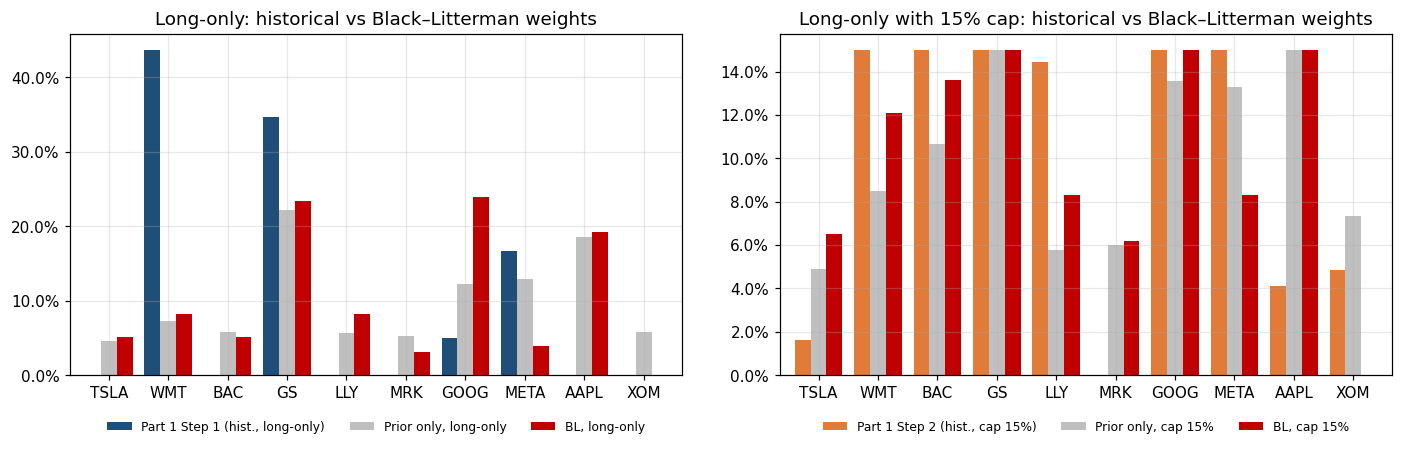

,"BL, long-only","BL, cap 15%",Part 1 Step 1,Part 1 Step 2
Exp. excess return under BL (ann.),0.1708,0.1605,0.1390,0.1473
Volatility under BL (ann.),0.2001,0.1905,0.1921,0.1842
Sharpe under BL,0.8538,0.8422,0.7236,0.7998


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cmp_[['Part 1 Step 1 (hist., long-only)', 'Prior only, long-only', 'BL, long-only']].plot.bar(ax=axes[0], width=0.8, color=['#1f4e79', '#bfbfbf', '#c00000'])
cmp_[['Part 1 Step 2 (hist., cap 15%)', 'Prior only, cap 15%', 'BL, cap 15%']].plot.bar(ax=axes[1], width=0.8, color=['#e07b39', '#bfbfbf', '#c00000'])
for a, t in zip(axes, ['Long-only', 'Long-only with 15% cap']):
    a.set_title(f'{t}: historical vs Black–Litterman weights'); a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    a.tick_params(axis='x', rotation=0); a.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig('figures/fig8_bl_weights.png', bbox_inches='tight'); plt.show()

bl_stats = pd.DataFrame({k: port_stats(v, mu_bl10, S_bl10, 0.0) for k, v in
                         {'BL, long-only': wb_lo, 'BL, cap 15%': wb_15, 'Part 1 Step 1': w1, 'Part 1 Step 2': w2}.items()},
                        index=['Exp. excess return under BL (ann.)', 'Volatility under BL (ann.)', 'Sharpe under BL'])
display(bl_stats.round(4))

## Step 9(e) – Observations

Compared with Part 1, the BL portfolios are far less extreme. They hold all or nearly all ten names instead of piling into WMT/GS, because the starting point is market equilibrium rather than noisy historical averages. Our views show up clearly in the weights: **GOOG** rises to 24% (long-only) or the 15% cap, **META** is cut to 4–8%, and **XOM** is dropped completely. LLY gains a little and MRK loses a little. The constraints damp the views: measured against the no-view (prior-only) portfolio, total weight change is 0.35 long-only but 0.25 with the 15% cap, because GS, AAPL and GOOG are already stuck at the cap and cannot absorb any further tilt. In the unconstrained 11-asset solution the views appear exactly as long/short tilts: GOOG +8.2 pp vs META –7.7 pp, XOM –11.5 pp, and LLY +1.6 pp vs MRK –1.5 pp.

